# 05 — Customer Cancellation Analysis

## Objective
Analyse customer cancellation behaviour across RFM segments to identify cancellation patterns, financial impact, and potential signals of customer disengagement.

## Research Questions
1. How prevalent are cancellations among identified customers?
2. How does cancellation activity vary across customer segments?
3. Which transaction types contribute most to cancellation value?
4. Are cancellation values concentrated in a small number of exceptional transactions?
5. Does cancellation activity provide supplementary information for sales prioritisation?

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# File paths
DATA_FILE = "../data/clean/transactions_clean.parquet"
SEGMENT_FILE = "../outputs/tables/customer_rfm_segments.csv"

# Load datasets
transactions = pd.read_parquet(DATA_FILE)
customer_segments = pd.read_csv(SEGMENT_FILE)

# Recreate line value for cancellation calculations
transactions["line_value"] = (
    transactions["Quantity"] * transactions["Price"]
)

# Validate loaded data
print("Transactions shape:", transactions.shape)
print("Customer segments shape:", customer_segments.shape)
print("Unique segmented customers:",
      customer_segments["Customer ID"].nunique())

print("\nCustomer segments:")
display(
    customer_segments["customer_segment_refined"]
    .value_counts()
    .rename_axis("Segment")
    .reset_index(name="Customers")
)

Transactions shape: (1041449, 14)
Customer segments shape: (5853, 9)
Unique segmented customers: 5853

Customer segments:


,Segment,Customers
0,Hibernating,1615
1,Champions,1266
2,Other / Developing,859
3,Potential Loyalists,716
4,Loyal Customers,590
5,At Risk,388
6,High-value At Risk,317
7,New Customers,75
8,Non-positive Value,27


In [2]:
# Keep cancellation transactions with an identified Customer ID
cancellations = transactions[
    transactions["Customer ID"].notna()
    & transactions["is_cancellation"]
].copy()

# Attach the RFM segment to each cancellation record
cancellations = cancellations.merge(
    customer_segments[
        ["Customer ID", "customer_segment_refined"]
    ],
    on="Customer ID",
    how="inner"
)

# Validate cancellation dataset
print("Cancellation rows:", len(cancellations))
print("Unique cancellation invoices:",
      cancellations["Invoice"].nunique())
print("Customers with cancellation activity:",
      cancellations["Customer ID"].nunique())
print("Total cancellation value: £{:,.2f}".format(
    cancellations["line_value"].sum()
))

display(cancellations.head())

Cancellation rows: 18276
Unique cancellation invoices: 7794
Customers with cancellation activity: 2496
Total cancellation value: £-964,661.94


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Sheet,is_exact_duplicate,is_cancellation,is_product,line_type,line_value,customer_segment_refined
0,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,16321,Australia,Year 2009-2010,False,True,True,product,-35.4,Loyal Customers
1,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,16321,Australia,Year 2009-2010,False,True,True,product,-9.9,Loyal Customers
2,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,16321,Australia,Year 2009-2010,False,True,True,product,-17.0,Loyal Customers
3,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,16321,Australia,Year 2009-2010,False,True,True,product,-12.6,Loyal Customers
4,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,16321,Australia,Year 2009-2010,False,True,True,product,-35.4,Loyal Customers


In [3]:
# Check whether any cancellation records have missing segment labels
print(
    "Missing segment labels:",
    cancellations["customer_segment_refined"].isna().sum()
)

# Check the distribution of cancellation records by segment
display(
    cancellations["customer_segment_refined"]
    .value_counts()
    .rename_axis("Segment")
    .reset_index(name="Cancellation Rows")
)

# Inspect the distinct segment labels
print(
    "\nDistinct segment labels:",
    sorted(cancellations["customer_segment_refined"].dropna().unique())
)

Missing segment labels: 0


,Segment,Cancellation Rows
0,Champions,11652
1,Loyal Customers,2069
2,High-value At Risk,1416
3,Hibernating,806
4,Potential Loyalists,757
5,Other / Developing,644
6,At Risk,562
7,Non-positive Value,355
8,New Customers,15



Distinct segment labels: ['At Risk', 'Champions', 'Hibernating', 'High-value At Risk', 'Loyal Customers', 'New Customers', 'Non-positive Value', 'Other / Developing', 'Potential Loyalists']


In [4]:
# Summarise cancellation activity at customer level
customer_cancellation = (
    cancellations.groupby("Customer ID")
    .agg(
        cancellation_invoices=("Invoice", "nunique"),
        cancellation_rows=("Invoice", "size"),
        cancellation_value=("line_value", "sum")
    )
    .reset_index()
)

# Add cancellation information to the complete RFM customer base
customer_cancellation = customer_segments[
    ["Customer ID", "customer_segment_refined"]
].merge(
    customer_cancellation,
    on="Customer ID",
    how="left"
)

# Customers without cancellations should have zero values
cancellation_columns = [
    "cancellation_invoices",
    "cancellation_rows",
    "cancellation_value"
]

customer_cancellation[cancellation_columns] = (
    customer_cancellation[cancellation_columns].fillna(0)
)

# Create a binary cancellation indicator
customer_cancellation["has_cancelled"] = (
    customer_cancellation["cancellation_invoices"] > 0
)

print("Total RFM customers:", len(customer_cancellation))
print(
    "Customers with cancellations:",
    customer_cancellation["has_cancelled"].sum()
)
print(
    "Customers without cancellations:",
    (~customer_cancellation["has_cancelled"]).sum()
)

display(customer_cancellation.head())

Total RFM customers: 5853
Customers with cancellations: 2496
Customers without cancellations: 3357


,Customer ID,customer_segment_refined,cancellation_invoices,cancellation_rows,cancellation_value,has_cancelled
0,12346,Non-positive Value,5.0,14.0,-77621.14,True
1,12347,Champions,0.0,0.0,0.00,False
2,12348,Loyal Customers,0.0,0.0,0.00,False
3,12349,Potential Loyalists,1.0,5.0,-24.15,True
4,12350,Hibernating,0.0,0.0,0.00,False


In [5]:
# Aggregate cancellation behaviour by customer segment
segment_cancellation = (
    customer_cancellation.groupby("customer_segment_refined")
    .agg(
        total_customers=("Customer ID", "nunique"),
        customers_with_cancellations=("has_cancelled", "sum"),
        total_cancellation_invoices=("cancellation_invoices", "sum"),
        total_cancellation_value=("cancellation_value", "sum")
    )
    .reset_index()
)

# Calculate cancellation incidence
segment_cancellation["cancellation_incidence_pct"] = (
    segment_cancellation["customers_with_cancellations"]
    / segment_cancellation["total_customers"] * 100
)

# Calculate average cancellation value per customer
segment_cancellation["avg_cancellation_value_per_customer"] = (
    segment_cancellation["total_cancellation_value"]
    / segment_cancellation["total_customers"]
)

# Sort by cancellation incidence
segment_cancellation = segment_cancellation.sort_values(
    "cancellation_incidence_pct",
    ascending=False
)

# Format output
display(
    segment_cancellation.round({
        "cancellation_incidence_pct": 2,
        "total_cancellation_value": 2,
        "avg_cancellation_value_per_customer": 2
    })
)

,customer_segment_refined,total_customers,customers_with_cancellations,total_cancellation_invoices,total_cancellation_value,cancellation_incidence_pct,avg_cancellation_value_per_customer
6,Non-positive Value,27,26,41.0,-122639.17,96.30,-4542.19
1,Champions,1266,984,4889.0,-420306.35,77.73,-332.00
3,High-value At Risk,317,199,579.0,-87896.47,62.78,-277.28
4,Loyal Customers,590,361,923.0,-47224.37,61.19,-80.04
0,At Risk,388,182,290.0,-10533.08,46.91,-27.15
8,Potential Loyalists,716,235,347.0,-195469.19,32.82,-273.00
7,Other / Developing,859,212,338.0,-64222.69,24.68,-74.76
2,Hibernating,1615,289,378.0,-16243.44,17.89,-10.06
5,New Customers,75,8,9.0,-127.18,10.67,-1.70


In [6]:
# Analyse cancellations by transaction type
cancellation_type = (
    cancellations.groupby("line_type")
    .agg(
        cancellation_rows=("Invoice", "size"),
        cancellation_invoices=("Invoice", "nunique"),
        cancellation_value=("line_value", "sum")
    )
    .reset_index()
)

# Calculate share of cancellation rows
cancellation_type["row_share_pct"] = (
    cancellation_type["cancellation_rows"]
    / cancellation_type["cancellation_rows"].sum() * 100
)

# Calculate share of total cancellation value
# Absolute values are used because cancellation values are negative
cancellation_type["value_share_pct"] = (
    cancellation_type["cancellation_value"].abs()
    / cancellation_type["cancellation_value"].abs().sum() * 100
)

# Sort by absolute cancellation value
cancellation_type = cancellation_type.sort_values(
    "cancellation_value",
    ascending=True
)

display(
    cancellation_type.round({
        "cancellation_value": 2,
        "row_share_pct": 2,
        "value_share_pct": 2
    })
)

,line_type,cancellation_rows,cancellation_invoices,cancellation_value,row_share_pct,value_share_pct
3,product,17554,7257,-711603.52,96.05,73.77
0,adjustment,513,451,-230451.36,2.81,23.89
2,postage,186,184,-14584.53,1.02,1.51
1,other,23,23,-8022.53,0.13,0.83


In [7]:
# Aggregate cancellation transactions at invoice level
top_cancellations = (
    cancellations.groupby(
        ["Customer ID", "Invoice", "customer_segment_refined"]
    )
    .agg(
        cancellation_date=("InvoiceDate", "min"),
        cancellation_rows=("Invoice", "size"),
        cancellation_value=("line_value", "sum")
    )
    .reset_index()
)

# Sort by absolute cancellation value
top_cancellations["absolute_value"] = (
    top_cancellations["cancellation_value"].abs()
)

top_15_cancellations = (
    top_cancellations
    .sort_values("absolute_value", ascending=False)
    .head(15)
    .copy()
)

# Calculate concentration of cancellation value
top_15_value = top_15_cancellations["absolute_value"].sum()
total_cancellation_value = cancellations["line_value"].abs().sum()

print("Total unique cancellation invoices:",
      len(top_cancellations))

print("Top 15 cancellation value: £{:,.2f}".format(top_15_value))

print("Share of total cancellation value: {:.2f}%".format(
    top_15_value / total_cancellation_value * 100
))

display(
    top_15_cancellations.drop(columns="absolute_value")
    .round({"cancellation_value": 2})
    .reset_index(drop=True)
)

Total unique cancellation invoices: 7794
Top 15 cancellation value: £405,507.34
Share of total cancellation value: 42.04%


,Customer ID,Invoice,customer_segment_refined,cancellation_date,cancellation_rows,cancellation_value
0,16446,C581484,Potential Loyalists,2011-12-09 09:27:00,1,-168469.60
1,12346,C541433,Non-positive Value,2011-01-18 10:17:00,1,-77183.60
2,15098,C556445,Other / Developing,2011-06-10 15:31:00,1,-38970.00
3,15749,C550456,High-value At Risk,2011-04-18 13:08:00,5,-22998.40
4,14277,C524235,Champions,2010-09-28 11:02:00,45,-11880.84
5,16029,C570556,Champions,2011-10-11 11:10:00,12,-11816.64
6,14063,C525398,Non-positive Value,2010-10-05 11:47:00,1,-10468.80
7,14063,C522793,Non-positive Value,2010-09-16 14:53:00,1,-10468.80
8,17949,C496116,Champions,2010-01-29 11:05:00,1,-8985.60
9,12536,C573079,Other / Developing,2011-10-27 14:15:00,1,-8322.12


In [8]:
# Identify the top 15 cancellation invoices
top_15_keys = top_15_cancellations[
    ["Customer ID", "Invoice"]
].drop_duplicates()

# Mark cancellation records belonging to the top 15 invoices
cancellations_sensitivity = cancellations.merge(
    top_15_keys.assign(is_top_15=True),
    on=["Customer ID", "Invoice"],
    how="left"
)

# Retain all cancellation records except the top 15 invoices
cancellations_sensitivity["is_top_15"] = (
    cancellations_sensitivity["is_top_15"].fillna(False)
)

adjusted_cancellations = cancellations_sensitivity[
    ~cancellations_sensitivity["is_top_15"]
].copy()

# Compare original and adjusted cancellation value by segment
original_by_segment = (
    cancellations.groupby("customer_segment_refined")["line_value"]
    .sum()
    .rename("original_cancellation_value")
)

adjusted_by_segment = (
    adjusted_cancellations.groupby("customer_segment_refined")["line_value"]
    .sum()
    .rename("adjusted_cancellation_value")
)

sensitivity = pd.concat(
    [original_by_segment, adjusted_by_segment],
    axis=1
).fillna(0).reset_index()

sensitivity["impact_of_top_15"] = (
    sensitivity["original_cancellation_value"]
    - sensitivity["adjusted_cancellation_value"]
)

sensitivity["reduction_pct"] = (
    sensitivity["impact_of_top_15"].abs()
    / sensitivity["original_cancellation_value"].abs() * 100
)

sensitivity = sensitivity.sort_values(
    "impact_of_top_15",
    ascending=False
)

display(sensitivity.round(2))

print(
    "\nOriginal cancellation value: £{:,.2f}".format(
        cancellations["line_value"].sum()
    )
)

print(
    "Adjusted cancellation value: £{:,.2f}".format(
        adjusted_cancellations["line_value"].sum()
    )
)


C:\Users\monug\AppData\Local\Temp\ipykernel_12936\2799676321.py:15: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  cancellations_sensitivity["is_top_15"].fillna(False)


,customer_segment_refined,original_cancellation_value,adjusted_cancellation_value,impact_of_top_15,reduction_pct
0,At Risk,-10533.08,-10533.08,0.00,0.00
2,Hibernating,-16243.44,-16243.44,0.00,0.00
4,Loyal Customers,-47224.37,-47224.37,0.00,0.00
5,New Customers,-127.18,-127.18,0.00,0.00
3,High-value At Risk,-87896.47,-57397.75,-30498.72,34.70
7,Other / Developing,-64222.69,-16930.57,-47292.12,73.64
1,Champions,-420306.35,-366225.44,-54080.91,12.87
6,Non-positive Value,-122639.17,-17473.18,-105165.99,85.75
8,Potential Loyalists,-195469.19,-26999.59,-168469.60,86.19



Original cancellation value: £-964,661.94
Adjusted cancellation value: £-559,154.60


In [9]:
# Total purchase invoices by segment
purchase_by_segment = (
    customer_segments.groupby("customer_segment_refined")
    .agg(
        total_purchase_invoices=("frequency", "sum")
    )
    .reset_index()
)

# Combine purchase and cancellation invoice counts
cancellation_ratio = segment_cancellation.merge(
    purchase_by_segment,
    on="customer_segment_refined",
    how="left"
)

# Calculate cancellation-to-purchase invoice ratio
cancellation_ratio["cancellation_to_purchase_ratio_pct"] = (
    cancellation_ratio["total_cancellation_invoices"]
    / cancellation_ratio["total_purchase_invoices"] * 100
)

cancellation_ratio = cancellation_ratio.sort_values(
    "cancellation_to_purchase_ratio_pct",
    ascending=False
)

display(
    cancellation_ratio[
        [
            "customer_segment_refined",
            "total_customers",
            "total_purchase_invoices",
            "total_cancellation_invoices",
            "cancellation_to_purchase_ratio_pct"
        ]
    ].round(2)
)

,customer_segment_refined,total_customers,total_purchase_invoices,total_cancellation_invoices,cancellation_to_purchase_ratio_pct
0,Non-positive Value,27,41,41.0,100.00
2,High-value At Risk,317,2360,579.0,24.53
1,Champions,1266,21835,4889.0,22.39
6,Other / Developing,859,1724,338.0,19.61
4,At Risk,388,1498,290.0,19.36
3,Loyal Customers,590,4887,923.0,18.89
7,Hibernating,1615,2112,378.0,17.90
5,Potential Loyalists,716,2065,347.0,16.80
8,New Customers,75,75,9.0,12.00


In [10]:
from pathlib import Path

output_folder = Path("../outputs/tables")
output_folder.mkdir(parents=True, exist_ok=True)

# Save segment-level cancellation analysis
segment_cancellation.to_csv(
    output_folder / "cancellation_by_segment.csv",
    index=False
)

# Save cancellation transaction type analysis
cancellation_type.to_csv(
    output_folder / "cancellation_by_transaction_type.csv",
    index=False
)

# Save top 15 cancellation invoices
top_15_cancellations.drop(
    columns="absolute_value"
).to_csv(
    output_folder / "top_15_cancellation_invoices.csv",
    index=False
)

# Save sensitivity analysis
sensitivity.to_csv(
    output_folder / "cancellation_sensitivity.csv",
    index=False
)

# Save cancellation-to-purchase invoice ratio
cancellation_ratio.to_csv(
    output_folder / "cancellation_to_purchase_ratio.csv",
    index=False
)

print("Five cancellation analysis tables exported successfully.")

Five cancellation analysis tables exported successfully.


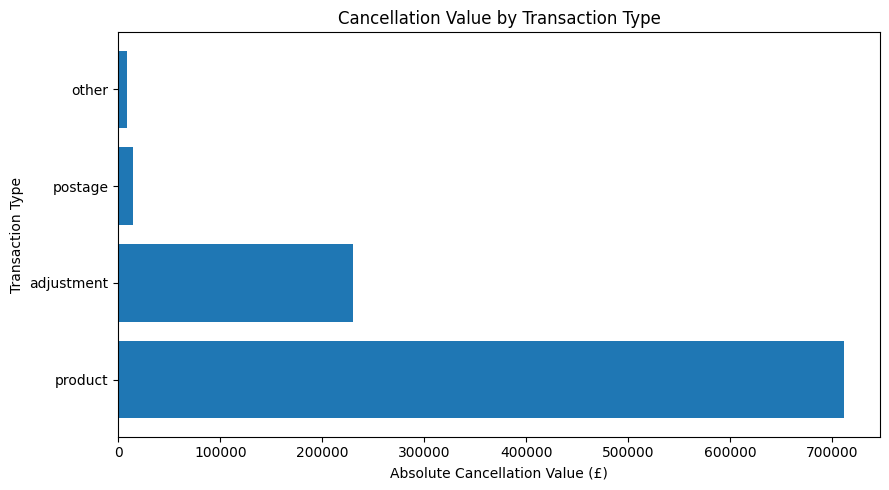

In [ ]:
# Prepare data for plotting
plot_data = cancellation_type.sort_values(
    "cancellation_value",
    ascending=True
)

plt.figure(figsize=(9, 5))

bars = plt.barh(
    plot_data["line_type"],
    plot_data["cancellation_value"].abs()
)

plt.title("Cancellation Value by Transaction Type")
plt.xlabel("Absolute Cancellation Value (£)")
plt.ylabel("Transaction Type")

plt.bar_label(
    bars,
    labels=[
        f"£{value:,.0f}"
        for value in plot_data["cancellation_value"].abs()
    ],
    padding=5
)

plt.xlim(
    0,
    plot_data["cancellation_value"].abs().max() * 1.18
)

plt.tight_layout()

plt.savefig(
    chart_folder / "05_cancellation_value_by_type.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Key Findings and Business Implications

### 1. Cancellation prevalence
Of the 5,853 customers included in the RFM analysis, 2,496 (42.65%) had at least one cancellation. Cancellation activity is therefore widespread across the customer base.

### 2. Segment-level cancellation patterns
Champions recorded the highest number of customers with cancellations (984), representing 77.73% of the segment. High-value At Risk customers also showed substantial cancellation incidence at 62.78%. This makes cancellation history a useful supplementary indicator when prioritising customer outreach.

### 3. Financial concentration
The 15 largest cancellation invoices accounted for 42.04% of total cancellation value. Potential Loyalists and Non-positive Value were particularly sensitive to these exceptional events. Therefore, cancellation exposure should be assessed using both aggregate and adjusted values.

### 4. Transaction-type contribution
Product cancellations represented 73.77% of cancellation value. Adjustments contributed a further 23.89%, despite accounting for only 2.81% of cancellation rows. This indicates that non-product adjustments deserve separate monitoring.

### 5. Implications for sales prioritisation
High-value At Risk customers warrant attention because they combine meaningful historical customer value, declining recency and substantial cancellation activity. Champions should also be monitored to protect valuable relationships.

### Limitations
- Cancellation activity does not necessarily indicate customer churn.
- Cancellation invoices are not necessarily matched to their original purchase invoices.
- The cancellation-to-purchase invoice ratio is not a product return rate.
- Cancellation analysis is descriptive and has not established predictive or causal relationships with future customer inactivity.
- Monetary value represents net revenue, not profit, because product cost information is unavailable.

Overall, cancellation activity provides an additional dimension for customer monitoring, but should be interpreted alongside RFM metrics rather than used as a standalone churn indicator.